# Operating modes: train and test data

Turns the hand-labelled stretches in `labels.csv` into one row per vessel-minute, with
features computed from `raw/<vessel>/<YYYY-MM-DD>.parquet`, splits them so no port call
or voyage ends up on both sides, and fits a `HistGradientBoostingClassifier`.

Writes `data/labelled.parquet` (every labelled minute, with a `split` column),
`data/train.parquet` and `data/test.parquet`.

**Choices worth knowing about**
- Every vessel is resampled to one row per minute and every window is a number of minutes,
  so a feature means the same on the 5 s, 15 s and 60 s loggers.
- Power, shaft speed, fuel, draught, through-water speed and position spread are scaled by
  the vessel register. Raw position, sea temperature and absolute kW, rpm and metres are left
  out: they tell the model which ship or which port it is looking at, not what it is doing.
  Torque is left out because power = torque × shaft speed.
- Windows are centred, they look ahead as well as back. Right for labelling history offline,
  not a real-time classifier.
- Neighbouring minutes are nearly identical, so the split is by **episode** (a port call or
  voyage), never by row.

In [33]:
from pathlib import Path

ROOT = Path(".")            # package folder with labels.csv, vessels.csv and raw/
OUT = Path("data")

SPLIT = "time"              # "time": episodes starting on/after CUTOFF are test
                            # "vessel": TEST_VESSEL is test, the other labelled vessel is train
CUTOFF = "2025-07-01"
TEST_VESSEL = "wendover-trader"

ON_DISAGREEMENT = "drop"    # both labellers labelled a minute and disagree: "drop", "A" or "B"
MARGIN_MIN = 5              # leave training rows this many minutes from a label boundary out
PAD_DAYS = 2                # days of context loaded around each labelled stretch
GAP_HOURS = 6               # stretches less than this apart belong to the same episode

In [34]:
import re

import numpy as np
import pandas as pd

pd.set_option("display.width", 200)

MODES = ["sea_passage", "manoeuvring", "at_anchor", "in_port", "cargo_operations"]

RAW_COLUMNS = [
    "speed_stw_kn", "speed_sog_kn", "heading_deg", "latitude_gps_deg", "longitude_gps_deg",
    "rudder_angle_deg", "draught_average_m", "trim_deg", "heel_deg",
    "speed_wind_relative_kn", "direction_wind_relative_deg",
    "power_main_engine_total_kw", "speed_main_engine_average_rpm",
    "fuelflow_main_engine_total_kgh",
]

# Supplier Y (Calder Trader, Harrowgate) may name columns differently. Both labelled
# vessels are supplier X, so this only matters once you run on the other two.
# Map supplier-Y names to the names above, e.g. {"stw_knots": "speed_stw_kn"}.
COLUMN_ALIASES = {}

REGISTER_COLUMNS = [
    "length_pp_m", "installed_power_kw", "max_shaft_speed_rpm", "design_speed_kn",
    "draught_ballast_m", "draught_laden_m",
]

META = ["vessel", "timestamp", "episode", "label_A", "label_B", "mode", "near_boundary", "split"]


def slug(name):
    """'Wendover Trader' -> 'wendover-trader', the folder name under raw/."""
    return re.sub(r"[^a-z0-9]+", "-", str(name).lower()).strip("-")

## 1. Labels and episodes

An episode is a port call or voyage: stretches from either labeller that are less than
`GAP_HOURS` apart. The split later keeps each episode on one side.

In [35]:
def load_labels(path, gap_hours=6):
    lab = pd.read_csv(path, parse_dates=["start", "end"])
    # pandas 3 parses these at microsecond resolution, the parquet files are in
    # nanoseconds, and interval lookups refuse to mix the two. Use ns everywhere.
    lab[["start", "end"]] = lab[["start", "end"]].astype("datetime64[ns]")
    lab["vessel"] = lab["vessel"].map(slug)
    lab["labeller"] = lab["labelled_by"].astype(str).str.split().str[-1]   # 'labeller A' -> 'A'

    if unknown := set(lab["mode"]) - set(MODES):
        raise ValueError(f"unknown modes in labels: {unknown}")
    if unknown := set(lab["labeller"]) - {"A", "B"}:
        raise ValueError(f"expected labellers A and B, also found {unknown}")
    if (lab["end"] <= lab["start"]).any():
        raise ValueError("some stretches end before they start")
    for (vessel, who), g in lab.groupby(["vessel", "labeller"]):
        g = g.sort_values("start")
        if (g["start"].to_numpy()[1:] < g["end"].to_numpy()[:-1]).any():
            raise ValueError(f"overlapping stretches for {vessel}, labeller {who}")

    lab = lab.sort_values(["vessel", "start"]).reset_index(drop=True)
    reach = lab.groupby("vessel")["end"].transform(lambda s: s.cummax().shift())
    new = reach.isna() | (lab["start"] > reach + pd.Timedelta(hours=gap_hours))
    n = new.astype(int).groupby(lab["vessel"]).cumsum()
    lab["episode"] = lab["vessel"] + "-" + n.astype(str).str.zfill(2)
    return lab


lab = load_labels(ROOT / "labels.csv", GAP_HOURS)
lab["hours"] = (lab["end"] - lab["start"]).dt.total_seconds() / 3600

episodes = lab[lab["labeller"] == "A"].pivot_table(
    index="episode", columns="mode", values="hours", aggfunc="sum").reindex(columns=MODES).round(1)
episodes.insert(0, "start", lab.groupby("episode")["start"].min())
episodes.insert(1, "both_labellers", lab.groupby("episode")["labeller"].nunique() == 2)
episodes.sort_values("start")

mode,start,both_labellers,sea_passage,manoeuvring,at_anchor,in_port,cargo_operations
episode,,,,,,,
brayton-trader-01,2024-08-31 23:55:00,True,30.2,3.5,NaN,14.0,62.2
wendover-trader-01,2024-08-31 23:55:00,True,26.0,1.9,17.9,16.2,42.5
brayton-trader-02,2024-09-20 20:05:00,True,57.4,4.3,NaN,16.8,45.0
brayton-trader-03,2024-12-28 18:20:00,True,40.7,5.4,NaN,14.2,38.8
wendover-trader-02,2024-12-30 01:20:00,True,55.2,5.8,28.5,8.3,58.8
brayton-trader-04,2025-01-15 01:30:00,False,56.6,4.2,34.7,24.3,69.3
wendover-trader-03,2025-01-19 07:55:00,True,103.1,5.2,NaN,21.6,57.3
brayton-trader-05,2025-03-03 19:40:00,False,24.8,NaN,7.9,NaN,NaN
brayton-trader-06,2025-03-24 14:10:00,False,150.4,3.8,NaN,16.5,34.3


## 2. Inter-rater agreement: the ceiling

Labeller A against labeller B on every minute both labelled. No model scored against these
labels can be expected to beat this. Per-mode F1 is symmetric, so it does not matter which
labeller is treated as the reference.

In [36]:
from sklearn.metrics import cohen_kappa_score, f1_score


def minute_labels(lab, who):
    parts = [
        pd.DataFrame({"vessel": r.vessel, "mode": r.mode,
                      "timestamp": pd.date_range(r.start, r.end, freq="min", inclusive="left")})
        for r in lab[lab["labeller"] == who].itertuples()
    ]
    return pd.concat(parts, ignore_index=True)


both = minute_labels(lab, "A").merge(minute_labels(lab, "B"),
                                     on=["vessel", "timestamp"], suffixes=("_A", "_B"))
a, b = both["mode_A"], both["mode_B"]
print(f"{len(both) / 60:.0f} h labelled by both: accuracy {np.mean(a == b):.3f}, "
      f"Cohen's kappa {cohen_kappa_score(a, b):.3f}, "
      f"macro F1 {f1_score(a, b, labels=MODES, average='macro'):.3f}")

rater_f1 = pd.Series(f1_score(a, b, labels=MODES, average=None), index=MODES, name="rater_f1")
display(rater_f1.round(3).to_frame())
display(pd.crosstab(a.rename("labeller A"), b.rename("labeller B")))   # minutes

774 h labelled by both: accuracy 0.914, Cohen's kappa 0.870, macro F1 0.826


,rater_f1
sea_passage,0.999
manoeuvring,0.944
at_anchor,0.557
in_port,0.692
cargo_operations,0.940


labeller B,at_anchor,cargo_operations,in_port,manoeuvring,sea_passage
labeller A,,,,,
at_anchor,1075,0,1710,0,0
cargo_operations,0,17020,1220,10,0
in_port,0,940,4430,5,0
manoeuvring,0,20,60,1170,20
sea_passage,0,0,0,25,18730


## 3. Raw data on a 1-minute grid

Only the days around labelled stretches are loaded, plus `PAD_DAYS` either side for window
context. Heading and wind direction are averaged as sine and cosine, never as angles, and
longitude is unwrapped so the date line does not look like a 360° jump.

In [37]:
def day_blocks(lab_v, pad_days):
    """Days to load around the labelled stretches, grouped into runs of consecutive days."""
    days = set()
    for r in lab_v.itertuples():
        days.update(pd.date_range((r.start - pd.Timedelta(days=pad_days)).normalize(),
                                  (r.end + pd.Timedelta(days=pad_days)).normalize(), freq="D"))
    days = sorted(days)
    blocks = [[days[0]]]
    for d in days[1:]:
        if d - blocks[-1][-1] == pd.Timedelta(days=1):
            blocks[-1].append(d)
        else:
            blocks.append([d])
    return blocks


def read_block(raw_dir, vessel, days):
    files = [raw_dir / vessel / f"{d:%Y-%m-%d}.parquet" for d in days]
    frames = [pd.read_parquet(f) for f in files if f.exists()]
    if not frames:
        return None
    df = pd.concat(frames, ignore_index=True).rename(columns=COLUMN_ALIASES)
    if missing := [c for c in ["timestamp", *RAW_COLUMNS] if c not in df.columns]:
        raise KeyError(f"{vessel}: missing columns {missing}; has {list(df.columns)}. "
                       "Add the supplier's names to COLUMN_ALIASES.")
    ts = (pd.to_datetime(df["timestamp"], utc=True).dt.tz_localize(None)  # naive UTC, like labels.csv
          .astype("datetime64[ns]"))
    df = df.assign(timestamp=ts).set_index("timestamp").sort_index()
    return df.loc[~df.index.duplicated(), RAW_COLUMNS]


def to_minutes(raw):
    """One row per minute, whatever the logging interval. Minutes with no data are NaN."""
    x = raw.astype(float)
    for col, name in [("heading_deg", "heading"), ("direction_wind_relative_deg", "wind_dir")]:
        rad = np.deg2rad(x.pop(col))
        x[f"{name}_sin"], x[f"{name}_cos"] = np.sin(rad), np.cos(rad)
    lon = x["longitude_gps_deg"]
    ok = lon.notna()
    x.loc[ok, "longitude_gps_deg"] = np.rad2deg(np.unwrap(np.deg2rad(lon[ok].to_numpy())))
    m = x.resample("1min").mean()
    m["n_samples"] = raw["speed_sog_kn"].resample("1min").count()
    return m

## 4. Features

Vessel-agnostic: speeds near zero stay in knots (stopped is stopped on any ship), everything
that scales with ship size is divided by the register value. Window lengths are in minutes.

What each group is for:
- **speed, propulsion, steering**: sea passage against manoeuvring against stopped.
- **heading spread, position spread, wind from ahead, water past a still hull**: at anchor
  (swinging, head to wind, current under the hull) against alongside.
- **load rate, trim and heel spread**: cargo going in or out, the in port vs cargo operations
  split that speed cannot make.
- **hours since / until moving**: where in the port call a minute sits.

Window std is taken over minute means, so a 5 s logger (12 samples a minute) shows less
sensor noise than a 60 s one. Keep that in mind when checking transfer to Calder Trader and
Harrowgate.

In [38]:
FEATURES = [
    "sog_kn", "stw_frac", "stw_minus_sog_kn",
    "sog_mean_15", "sog_std_15", "sog_mean_60", "sog_std_60", "stw_minus_sog_mean_60",
    "power_frac", "rpm_frac", "fuel_frac",
    "power_frac_mean_15", "power_frac_std_15", "power_frac_mean_60", "power_frac_std_60",
    "rudder_abs_deg", "rudder_abs_mean_15", "rudder_std_15", "rudder_abs_mean_60", "rudder_std_60",
    "turn_rate_mean_15", "turn_rate_mean_60", "heading_circstd_60", "heading_circstd_180",
    "pos_spread_60_shiplengths", "pos_spread_180_shiplengths",
    "load_frac", "load_rate_abs_60", "load_rate_abs_180",
    "trim_std_60", "trim_std_180", "heel_std_60", "heel_std_180", "heel_abs_deg",
    "wind_rel_kn", "wind_rel_cos", "wind_rel_cos_mean_60",
    "hours_since_moving", "hours_until_moving",
]


def features(m, reg):
    """m: one vessel's minute grid. reg: its row from vessels.csv."""
    def win(s, w):
        return s.rolling(w, center=True, min_periods=max(1, w // 2))

    f = pd.DataFrame(index=m.index)

    sog, stw = m["speed_sog_kn"], m["speed_stw_kn"]
    f["sog_kn"] = sog
    f["stw_frac"] = stw / reg["design_speed_kn"]
    f["stw_minus_sog_kn"] = stw - sog            # water past a hull that stays put: anchored in a current
    for w in (15, 60):
        f[f"sog_mean_{w}"] = win(sog, w).mean()
        f[f"sog_std_{w}"] = win(sog, w).std()
    f["stw_minus_sog_mean_60"] = win(stw - sog, 60).mean()

    pf = m["power_main_engine_total_kw"] / reg["installed_power_kw"]
    f["power_frac"] = pf
    f["rpm_frac"] = m["speed_main_engine_average_rpm"] / reg["max_shaft_speed_rpm"]
    f["fuel_frac"] = m["fuelflow_main_engine_total_kgh"] / (0.185 * reg["installed_power_kw"])
    for w in (15, 60):
        f[f"power_frac_mean_{w}"] = win(pf, w).mean()
        f[f"power_frac_std_{w}"] = win(pf, w).std()

    rud = m["rudder_angle_deg"]
    f["rudder_abs_deg"] = rud.abs()
    for w in (15, 60):
        f[f"rudder_abs_mean_{w}"] = win(rud.abs(), w).mean()
        f[f"rudder_std_{w}"] = win(rud, w).std()

    hs, hc = m["heading_sin"], m["heading_cos"]
    heading = np.rad2deg(np.arctan2(hs, hc))
    turn = ((heading.diff() + 180) % 360 - 180).abs()          # degrees per minute
    for w in (15, 60):
        f[f"turn_rate_mean_{w}"] = win(turn, w).mean()
    for w in (60, 180):                                          # swinging at anchor vs fixed alongside
        r = np.hypot(win(hs, w).mean(), win(hc, w).mean()).clip(1e-9, 1)
        f[f"heading_circstd_{w}"] = np.rad2deg(np.sqrt(-2 * np.log(r)))

    lat = m["latitude_gps_deg"]
    north = lat * 111_320.0
    east = m["longitude_gps_deg"] * 111_320.0 * np.cos(np.deg2rad(lat))
    for w in (60, 180):                                          # metres of wander, in ship lengths
        spread = np.sqrt(win(north, w).var() + win(east, w).var())
        f[f"pos_spread_{w}_shiplengths"] = spread / reg["length_pp_m"]

    load = ((m["draught_average_m"] - reg["draught_ballast_m"])
            / (reg["draught_laden_m"] - reg["draught_ballast_m"]))
    f["load_frac"] = load                                        # 0 ballast, 1 laden
    smooth = win(load, 15).mean()
    for w in (60, 180):                                          # cargo going in or out, per hour
        half = w // 2
        f[f"load_rate_abs_{w}"] = ((smooth.shift(-half) - smooth.shift(half)) / (w / 60)).abs()

    for col, name in [("trim_deg", "trim"), ("heel_deg", "heel")]:   # std: trim sign convention differs per ship
        for w in (60, 180):
            f[f"{name}_std_{w}"] = win(m[col], w).std()
    f["heel_abs_deg"] = m["heel_deg"].abs()

    f["wind_rel_kn"] = m["speed_wind_relative_kn"]
    f["wind_rel_cos"] = m["wind_dir_cos"]                        # +1 dead ahead: an anchored ship lies head to wind
    f["wind_rel_cos_mean_60"] = win(m["wind_dir_cos"], 60).mean()

    moving = win(sog, 5).mean() > 3.0
    t = pd.Series(f.index, index=f.index)
    f["hours_since_moving"] = ((t - t.where(moving).ffill()).dt.total_seconds() / 3600).clip(upper=72)
    f["hours_until_moving"] = ((t.where(moving).bfill() - t).dt.total_seconds() / 3600).clip(upper=72)

    assert list(f.columns) == FEATURES, set(f.columns) ^ set(FEATURES)
    return f.astype("float32")

## 5. Build the labelled table

Each minute gets labeller A's and labeller B's mode. The final `mode` is whichever labeller
labelled it; where both did and they disagree, `ON_DISAGREEMENT` decides. Minutes with no
raw samples (telemetry link down) are dropped.

In [39]:
def label_at(times, stretches, column):
    """Value of `column` from the stretch [start, end) that contains each time, else None."""
    if stretches.empty:
        return np.full(len(times), None, dtype=object)
    stretches = stretches.sort_values("start")
    intervals = pd.IntervalIndex.from_arrays(stretches["start"].astype("datetime64[ns]"),
                                             stretches["end"].astype("datetime64[ns]"), closed="left")
    pos = intervals.get_indexer(pd.DatetimeIndex(times).astype("datetime64[ns]"))
    return np.where(pos >= 0, stretches[column].to_numpy(dtype=object)[pos], None)


def near_boundary(times, lab_v, margin_min):
    """True within margin_min of any stretch start or end, from either labeller."""
    b = np.unique(np.concatenate([lab_v["start"].to_numpy(), lab_v["end"].to_numpy()]).astype("datetime64[ns]"))
    t = pd.DatetimeIndex(times).to_numpy().astype("datetime64[ns]")
    i = np.searchsorted(b, t)
    left, right = b[np.clip(i - 1, 0, len(b) - 1)], b[np.clip(i, 0, len(b) - 1)]
    dist = np.minimum(np.abs(t - left), np.abs(right - t))
    return dist < np.timedelta64(int(margin_min * 60), "s")


def build_vessel(raw_dir, vessel, lab_v, reg, pad_days, margin_min):
    episodes = (lab_v.groupby("episode").agg(start=("start", "min"), end=("end", "max"))
                .reset_index())
    parts = []
    for days in day_blocks(lab_v, pad_days):
        raw = read_block(raw_dir, vessel, days)
        if raw is None:
            continue
        m = to_minutes(raw)
        f = features(m, reg)
        t = f.index
        a = label_at(t, lab_v[lab_v["labeller"] == "A"], "mode")
        b = label_at(t, lab_v[lab_v["labeller"] == "B"], "mode")
        keep = (pd.notna(a) | pd.notna(b)) & (m["n_samples"].to_numpy() > 0)
        part = f[keep].copy()
        part.insert(0, "vessel", vessel)
        part.insert(1, "timestamp", t[keep])
        part.insert(2, "episode", label_at(t[keep], episodes, "episode"))
        part.insert(3, "label_A", a[keep])
        part.insert(4, "label_B", b[keep])
        part.insert(5, "near_boundary", near_boundary(t[keep], lab_v, margin_min))
        parts.append(part)
    if not parts:
        raise FileNotFoundError(f"no raw files found for {vessel} under {raw_dir / vessel}")
    return pd.concat(parts, ignore_index=True)


reg = pd.read_csv(ROOT / "vessels.csv")
reg.index = reg["vessel"].map(slug)
if missing := [c for c in REGISTER_COLUMNS if c not in reg.columns]:
    raise KeyError(f"vessels.csv is missing {missing}")

df = pd.concat([
    build_vessel(ROOT / "raw", v, lab_v, reg.loc[v], PAD_DAYS, MARGIN_MIN)
    for v, lab_v in lab.groupby("vessel")
], ignore_index=True)

la, lb = df["label_A"], df["label_B"]
df["mode"] = la.where(la.notna(), lb)
disagree = la.notna() & lb.notna() & (la != lb)
if ON_DISAGREEMENT == "drop":
    df.loc[disagree, "mode"] = None
elif ON_DISAGREEMENT == "B":
    df.loc[disagree, "mode"] = lb[disagree]
print(f"{disagree.sum() / 60:.0f} h where the labellers disagree (ON_DISAGREEMENT={ON_DISAGREEMENT!r})")
df = df[df["mode"].notna()].reset_index(drop=True)
print(f"{len(df):,} labelled minutes, {df['episode'].nunique()} episodes")

67 h where the labellers disagree (ON_DISAGREEMENT='drop')
162,470 labelled minutes, 23 episodes


## 6. Split and save

By episode, so a port call never sits on both sides. With `SPLIT = "time"` an episode goes by
its start date, so one straddling the cutoff stays whole.

Rows next to a label boundary are left out of **train** only (boundaries are rounded to five
minutes). Test keeps every row so the score is honest; filter on `near_boundary` if you also
want it without them.

In [40]:
if SPLIT == "time":
    ep_start = lab.groupby("episode")["start"].min()
    test_eps = ep_start.index[ep_start >= pd.Timestamp(CUTOFF)]
    df["split"] = np.where(df["episode"].isin(test_eps), "test", "train")
elif SPLIT == "vessel":
    df["split"] = np.where(df["vessel"] == slug(TEST_VESSEL), "test", "train")
else:
    raise ValueError(f"SPLIT must be 'time' or 'vessel', not {SPLIT!r}")
df = df[META + FEATURES]

train = df[(df["split"] == "train") & ~df["near_boundary"]].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
assert not set(train["episode"]) & set(test["episode"]), "an episode is on both sides"

OUT.mkdir(parents=True, exist_ok=True)
df.to_parquet(OUT / "labelled.parquet", index=False)
train.to_parquet(OUT / "train.parquet", index=False)
test.to_parquet(OUT / "test.parquet", index=False)

print(f"train: {len(train):,} rows, {train['episode'].nunique()} episodes, {sorted(train['vessel'].unique())}")
print(f"test:  {len(test):,} rows, {test['episode'].nunique()} episodes, {sorted(test['vessel'].unique())}")
pd.concat({"train_hours": train["mode"].value_counts() / 60,
           "test_hours": test["mode"].value_counts() / 60}, axis=1).reindex(MODES).round(1)

train: 90,862 rows, 13 episodes, ['brayton-trader', 'wendover-trader']
test:  70,565 rows, 10 episodes, ['brayton-trader', 'wendover-trader']


,train_hours,test_hours
mode,,
sea_passage,811.2,707.1
manoeuvring,39.6,28.3
at_anchor,76.7,21.0
in_port,138.7,53.2
cargo_operations,448.2,366.5


## 7. Train and evaluate

- `early_stopping=False`: the built-in validation set is a random sample of rows, which
  leaks between neighbouring minutes just like a random split would.
- `class_weight="balanced"`: sea passage has about 20 times the hours of manoeuvring.

The model is scored per mode and set next to the rater agreement from step 2, the ceiling.

In [41]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

X_train, y_train = train[FEATURES], train["mode"]
X_test, y_test = test[FEATURES], test["mode"]

clf = HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                     max_iter=200, learning_rate=0.1, random_state=0)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print(classification_report(y_test, pred, labels=MODES, digits=3, zero_division=0))
display(pd.DataFrame({
    "model_f1": f1_score(y_test, pred, labels=MODES, average=None, zero_division=0),
    "rater_f1 (ceiling)": rater_f1,
    "test_hours": [np.sum(y_test == m) / 60 for m in MODES],
}, index=MODES).round(3))
display(pd.DataFrame(confusion_matrix(y_test, pred, labels=MODES),
                     index=pd.Index(MODES, name="true"), columns=pd.Index(MODES, name="predicted")))

                  precision    recall  f1-score   support

     sea_passage      0.999     0.998     0.999     42425
     manoeuvring      0.952     0.954     0.953      1700
       at_anchor      0.974     0.982     0.978      1260
         in_port      0.846     0.729     0.783      3190
cargo_operations      0.963     0.983     0.973     21990

        accuracy                          0.980     70565
       macro avg      0.947     0.929     0.937     70565
    weighted avg      0.979     0.980     0.979     70565



,model_f1,rater_f1 (ceiling),test_hours
sea_passage,0.999,0.999,707.083
manoeuvring,0.953,0.944,28.333
at_anchor,0.978,0.557,21.000
in_port,0.783,0.692,53.167
cargo_operations,0.973,0.940,366.500


predicted,sea_passage,manoeuvring,at_anchor,in_port,cargo_operations
true,,,,,
sea_passage,42354,57,12,2,0
manoeuvring,50,1621,0,29,0
at_anchor,0,7,1237,16,0
in_port,0,14,21,2324,831
cargo_operations,0,4,0,377,21609


## 8. Optional: cross-validation over episodes

The test set holds only a couple of anchorages, so its at_anchor score is noisy. Grouped
cross-validation on the training episodes uses every one of them as test once and gives a
steadier per-mode estimate. Use the same grouping for any hyperparameter tuning.

In [42]:
from sklearn.model_selection import GroupKFold, cross_val_predict

cv_pred = cross_val_predict(
    HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                   max_iter=200, learning_rate=0.1, random_state=0),
    X_train, y_train, groups=train["episode"], cv=GroupKFold(n_splits=5))
pd.DataFrame({
    "cv_f1": f1_score(y_train, cv_pred, labels=MODES, average=None, zero_division=0),
    "rater_f1 (ceiling)": rater_f1,
}, index=MODES).round(3)

,cv_f1,rater_f1 (ceiling)
sea_passage,0.994,0.999
manoeuvring,0.935,0.944
at_anchor,0.972,0.557
in_port,0.960,0.692
cargo_operations,0.988,0.940


## 9. Classify a time range and show the blocks

Give `show_range` a vessel and two times, for example the start and end of a block you plotted
in your own notebook. It loads the raw days around them, builds the same features, predicts
every minute, and turns the minutes into blocks: *from this time to this time is this mode*.
It then plots the blocks under the hand labels.

Two settings turn noisy minute predictions into clean blocks:
- `SMOOTH_MIN`: class probabilities are averaged over this many minutes before the mode is picked.
- `MIN_BLOCK_MIN`: a block shorter than this is merged into its longer neighbour.

Pick a range from the **test** episodes listed below. On a training range the model has already
seen the answers, so a good result there tells you nothing. `show_range` warns if you do.

In [43]:
# Ranges that are honest to test on: episodes the model never trained on
test_ranges = (lab[lab["episode"].isin(test["episode"].unique())]
               .groupby("episode").agg(vessel=("vessel", "first"), start=("start", "min"), end=("end", "max"))
               .sort_values("start"))
test_ranges

,vessel,start,end
episode,,,
brayton-trader-08,brayton-trader,2025-07-21 00:30:00,2025-07-26 16:40:00
wendover-trader-07,wendover-trader,2025-07-22 00:20:00,2025-07-23 05:35:00
wendover-trader-08,wendover-trader,2025-08-11 20:00:00,2025-08-14 17:40:00
brayton-trader-09,brayton-trader,2025-09-20 12:30:00,2025-09-30 13:25:00
wendover-trader-09,wendover-trader,2025-10-08 14:15:00,2025-10-13 05:30:00
brayton-trader-10,brayton-trader,2025-11-07 15:35:00,2025-11-11 21:35:00
wendover-trader-10,wendover-trader,2025-11-20 03:00:00,2025-11-26 00:35:00
wendover-trader-11,wendover-trader,2025-12-30 17:25:00,2026-01-05 08:35:00
wendover-trader-12,wendover-trader,2026-01-23 22:55:00,2026-01-28 11:15:00


In [44]:
import matplotlib.pyplot as plt

SMOOTH_MIN = 15       # average class probabilities over this many minutes
MIN_BLOCK_MIN = 10    # merge blocks shorter than this into a neighbour
MAX_GAP_MIN = 5       # a telemetry gap longer than this splits a block

MODE_COLOUR = {"sea_passage": "#cfe0f7", "manoeuvring": "#f7d2c0", "at_anchor": "#d6e9cf",
               "in_port": "#e4dcf0", "cargo_operations": "#fae3b8"}
PLOT_SIGNALS = ["speed_stw_kn", "speed_sog_kn", "power_main_engine_total_kw", "rudder_angle_deg",
                "draught_average_m", "heading_deg", "latitude_gps_deg"]
CIRCULAR = {"heading_deg", "direction_wind_relative_deg", "longitude_gps_deg"}


def predict_minutes(vessel, start, end):
    """Smoothed mode and confidence for every minute with data in [start, end)."""
    v = slug(vessel)
    days = list(pd.date_range((start - pd.Timedelta(days=PAD_DAYS)).normalize(),
                              (end + pd.Timedelta(days=PAD_DAYS)).normalize(), freq="D"))
    raw = read_block(ROOT / "raw", v, days)
    if raw is None:
        raise FileNotFoundError(f"no raw files for {v} between {days[0]:%Y-%m-%d} and {days[-1]:%Y-%m-%d}")
    m = to_minutes(raw)
    f = features(m, reg.loc[v])
    has_data = m["n_samples"].to_numpy() > 0

    # Predict on the padded days too, so the smoothing at the edges of the range has context
    proba = pd.DataFrame(np.nan, index=f.index, columns=clf.classes_)
    proba.loc[has_data] = clf.predict_proba(f.loc[has_data, FEATURES])
    smooth = proba.rolling(SMOOTH_MIN, center=True, min_periods=1).mean()

    keep = has_data & (f.index >= start) & (f.index < end)
    pred = pd.DataFrame({"mode": smooth[keep].idxmax(axis=1), "confidence": smooth[keep].max(axis=1)})
    return pred, raw.loc[start:end]


def to_blocks(pred):
    """Minute predictions -> blocks [start, end). Short blocks merge into their longer neighbour."""
    one, gap = pd.Timedelta(minutes=1), pd.Timedelta(minutes=MAX_GAP_MIN)
    shortest = pd.Timedelta(minutes=MIN_BLOCK_MIN)

    blocks = []
    for t, mode in pred["mode"].items():
        if blocks and mode == blocks[-1]["mode"] and t - blocks[-1]["end"] <= gap:
            blocks[-1]["end"] = t + one
        else:
            blocks.append({"start": t, "end": t + one, "mode": mode})

    def touching(i, j):            # j directly after i, no telemetry gap in between
        return blocks[j]["start"] - blocks[i]["end"] <= gap

    def length(i):
        return blocks[i]["end"] - blocks[i]["start"]

    while True:
        short = [i for i in range(len(blocks)) if length(i) < shortest
                 and ((i > 0 and touching(i - 1, i)) or (i + 1 < len(blocks) and touching(i, i + 1)))]
        if not short:
            break
        i = min(short, key=length)                                  # shortest first
        nbrs = [j for j in (i - 1, i + 1) if 0 <= j < len(blocks) and touching(min(i, j), max(i, j))]
        j = max(nbrs, key=length)
        if j < i:
            blocks[j]["end"] = blocks[i]["end"]
        else:
            blocks[j]["start"] = blocks[i]["start"]
        del blocks[i]
        k = 0                                                       # join same-mode blocks that now touch
        while k + 1 < len(blocks):
            if blocks[k]["mode"] == blocks[k + 1]["mode"] and touching(k, k + 1):
                blocks[k]["end"] = blocks[k + 1]["end"]
                del blocks[k + 1]
            else:
                k += 1

    out = pd.DataFrame(blocks, columns=["start", "end", "mode"])
    out["duration"] = (out["end"] - out["start"]).dt.round("min")
    out["confidence"] = [pred.loc[(pred.index >= r.start) & (pred.index < r.end), "confidence"].mean()
                         for r in out.itertuples()]
    return out


def plot_range(raw, blocks, lab_v, start, end, title, signals=PLOT_SIGNALS):
    strips = [(f"labeller {w}", lab_v[lab_v["labeller"] == w]) for w in ("A", "B")
              if (lab_v["labeller"] == w).any()] + [("classifier", blocks)]
    ns = len(strips)
    fig, axes = plt.subplots(ns + len(signals), 1, sharex=True,
                             figsize=(13, 0.4 * ns + 1.2 * len(signals) + 0.8),
                             gridspec_kw={"height_ratios": [0.4] * ns + [1.2] * len(signals)})
    for ax, (name, stretches) in zip(axes, strips):
        for r in stretches.itertuples():
            ax.axvspan(r.start, r.end, color=MODE_COLOUR[r.mode], linewidth=0)
        ax.set_yticks([])
        ax.grid(False)
        ax.text(1.01, 0.5, name, transform=ax.transAxes, fontsize=9, va="center",
                fontweight="bold" if name == "classifier" else "normal")
    for ax, col in zip(axes[ns:], signals):
        for r in blocks.itertuples():                                # signals shaded by the classifier
            ax.axvspan(r.start, r.end, color=MODE_COLOUR[r.mode], linewidth=0)
        if col in CIRCULAR:
            ax.plot(raw.index, raw[col], ".", color="#1c5cab", markersize=1)
        else:
            ax.plot(raw.index, raw[col], color="#1c5cab", linewidth=0.7)
        ax.text(1.01, 0.5, col, transform=ax.transAxes, fontsize=9, va="center")
        ax.tick_params(labelsize=7)
        ax.grid(True, color="#e6e5e0")
    axes[0].set_xlim(start, end)
    axes[0].set_title(title, loc="left", fontsize=10)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in MODE_COLOUR.values()]
    fig.legend(handles, list(MODE_COLOUR), ncol=5, loc="upper center", frameon=False, fontsize=8.5)
    fig.subplots_adjust(left=0.06, right=0.84, top=1 - 0.7 / fig.get_figheight(), bottom=0.04, hspace=0.3)
    plt.show()


def show_range(vessel, start, end, signals=PLOT_SIGNALS):
    """Classify [start, end) for one vessel, print the blocks, score them, plot them."""
    v, start, end = slug(vessel), pd.Timestamp(start), pd.Timestamp(end)

    seen = train[(train["vessel"] == v) & (train["timestamp"] >= start) & (train["timestamp"] < end)]
    if len(seen):
        print(f"WARNING: {len(seen) / 60:.0f} h of this range were used for training "
              f"({', '.join(seen['episode'].unique())}). The model has seen the answers here.\n")

    pred, raw = predict_minutes(v, start, end)
    blocks = to_blocks(pred)
    print(f"{vessel}, {start} to {end}: {len(blocks)} blocks")
    display(blocks.round({"confidence": 2}))

    lab_v = lab[(lab["vessel"] == v) & (lab["start"] < end) & (lab["end"] > start)]
    final = label_at(pred.index, blocks, "mode")                    # the mode each minute ended up in
    truth = label_at(pred.index, lab_v[lab_v["labeller"] == "A"], "mode")
    scored = pd.notna(truth)
    if scored.any():
        y, p = pd.Series(truth[scored], name="labeller A"), pd.Series(final[scored], name="classifier")
        print(f"Against labeller A on {scored.sum() / 60:.1f} labelled hours: "
              f"{np.mean(y.to_numpy() == p.to_numpy()):.1%} of minutes agree. Minutes per mode:")
        display(pd.crosstab(y, p))
    else:
        print("No hand labels in this range, nothing to score against.")

    plot_range(raw, blocks, lab_v, start, end, f"{vessel}, {start:%Y-%m-%d} to {end:%Y-%m-%d}", signals)
    return blocks

Change the vessel and the two times to any range you like; `blocks` holds the result as a
table. With `test_ranges` above you can loop over every test episode.


Wendover Trader, 2024-10-01 12:30:00 to 2025-03-01 13:25:00: 71 blocks


,start,end,mode,duration,confidence
0,2024-10-01 12:30:00,2024-10-10 20:13:00,sea_passage,9 days 07:43:00,1.00
1,2024-10-10 20:13:00,2024-10-10 23:08:00,manoeuvring,0 days 02:55:00,0.97
2,2024-10-10 23:08:00,2024-10-11 04:44:00,in_port,0 days 05:36:00,0.98
3,2024-10-11 04:44:00,2024-10-12 07:42:00,cargo_operations,1 days 02:58:00,1.00
4,2024-10-12 07:42:00,2024-10-12 19:59:00,in_port,0 days 12:17:00,0.99
...,...,...,...,...,...
66,2025-02-12 14:06:00,2025-02-13 04:07:00,in_port,0 days 14:01:00,1.00
67,2025-02-13 04:07:00,2025-02-14 19:44:00,cargo_operations,1 days 15:37:00,1.00
68,2025-02-14 19:44:00,2025-02-15 10:00:00,in_port,0 days 14:16:00,1.00
69,2025-02-15 10:00:00,2025-02-15 12:33:00,manoeuvring,0 days 02:33:00,0.97


Against labeller A on 343.9 labelled hours: 99.3% of minutes agree. Minutes per mode:


classifier,at_anchor,cargo_operations,in_port,manoeuvring,sea_passage
labeller A,,,,,
at_anchor,1710,0,0,0,0
cargo_operations,28,6928,0,14,0
in_port,0,45,1749,1,0
manoeuvring,17,0,19,609,15
sea_passage,0,0,0,2,9498


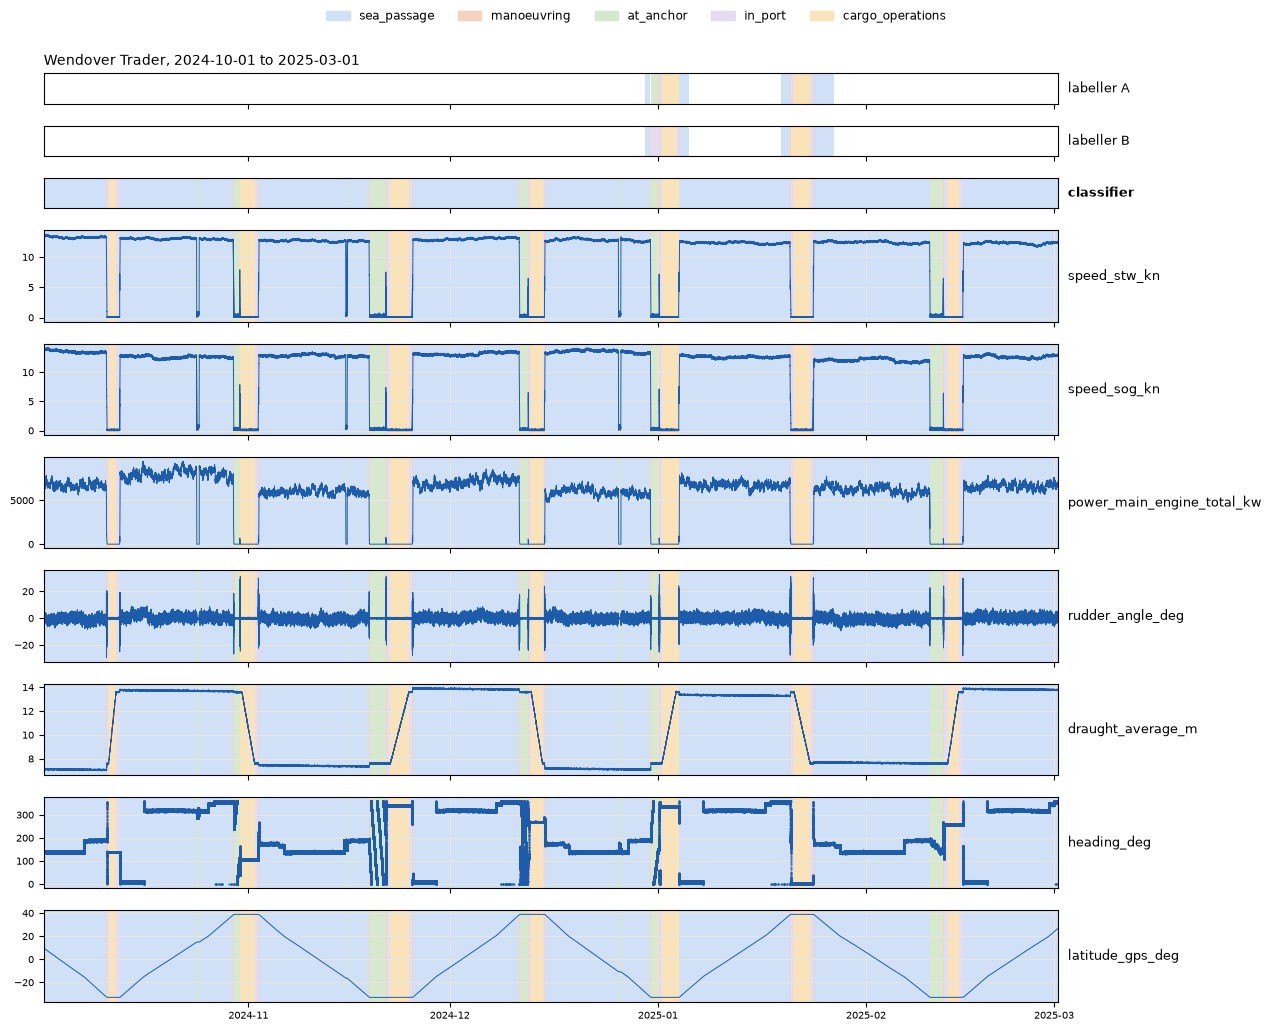

In [46]:
blocks = show_range("Wendover Trader", "2024-10-01 12:30", "2025-03-01 13:25")

,vessel,start,end,modes,n,trained_on_h
block,,,,,,
1,Brayton Trader,2024-09-01 00:00:00,2024-09-05 14:55:00,4,6,97.0
2,Brayton Trader,2024-09-20 20:05:00,2024-09-26 00:35:00,4,7,117.3
3,Brayton Trader,2024-12-28 18:20:00,2025-01-01 23:40:00,4,7,97.9
4,Brayton Trader,2025-01-15 01:30:00,2025-01-23 00:55:00,5,9,187.7
5,Brayton Trader,2025-03-03 19:40:00,2025-03-05 04:55:00,2,3,32.3
6,Brayton Trader,2025-03-24 14:10:00,2025-04-02 04:25:00,4,7,204.0
7,Brayton Trader,2025-04-12 06:35:00,2025-04-15 00:35:00,1,1,65.8
8,Brayton Trader,2025-07-21 00:30:00,2025-07-26 16:40:00,4,7,0.0
9,Brayton Trader,2025-09-20 12:30:00,2025-09-30 13:25:00,5,10,0.0


labeller A, block 22: Wendover Trader, 2025-12-30 17:25:00 to 2026-01-05 08:35:00

labeller A says:


,start,end,mode,duration
0,2025-12-30 17:25:00,2026-01-01 00:30:00,sea_passage,1 days 07:05:00
1,2026-01-01 00:30:00,2026-01-01 04:35:00,manoeuvring,0 days 04:05:00
2,2026-01-01 04:35:00,2026-01-01 08:15:00,in_port,0 days 03:40:00
3,2026-01-01 08:40:00,2026-01-04 07:10:00,cargo_operations,2 days 22:30:00
4,2026-01-04 07:40:00,2026-01-04 10:25:00,in_port,0 days 02:45:00
5,2026-01-04 10:55:00,2026-01-04 11:55:00,manoeuvring,0 days 01:00:00
6,2026-01-04 12:00:00,2026-01-05 08:35:00,sea_passage,0 days 20:35:00


classifier says:


,start,end,mode,duration,confidence
0,2025-12-30 17:25:00,2026-01-01 00:26:00,sea_passage,1 days 07:01:00,1.00
1,2026-01-01 00:26:00,2026-01-01 04:41:00,manoeuvring,0 days 04:15:00,0.98
2,2026-01-01 04:41:00,2026-01-01 09:10:00,in_port,0 days 04:29:00,0.98
3,2026-01-01 09:10:00,2026-01-04 07:25:00,cargo_operations,2 days 22:15:00,1.00
4,2026-01-04 07:25:00,2026-01-04 10:29:00,in_port,0 days 03:04:00,0.96
5,2026-01-04 10:29:00,2026-01-04 12:07:00,manoeuvring,0 days 01:38:00,0.96
6,2026-01-04 12:07:00,2026-01-05 08:35:00,sea_passage,0 days 20:28:00,1.00


99.4% of 133.7 labelled hours agree


,hours_A,hours_classifier,f1
sea_passage,51.67,51.48,1.00
manoeuvring,5.08,5.37,0.97
in_port,6.42,6.82,0.95
cargo_operations,70.50,70.00,1.00


classifier,cargo_operations,in_port,manoeuvring,sea_passage
labeller A,,,,
cargo_operations,4200,30,0,0
in_port,0,379,6,0
manoeuvring,0,0,305,0
sea_passage,0,0,11,3089


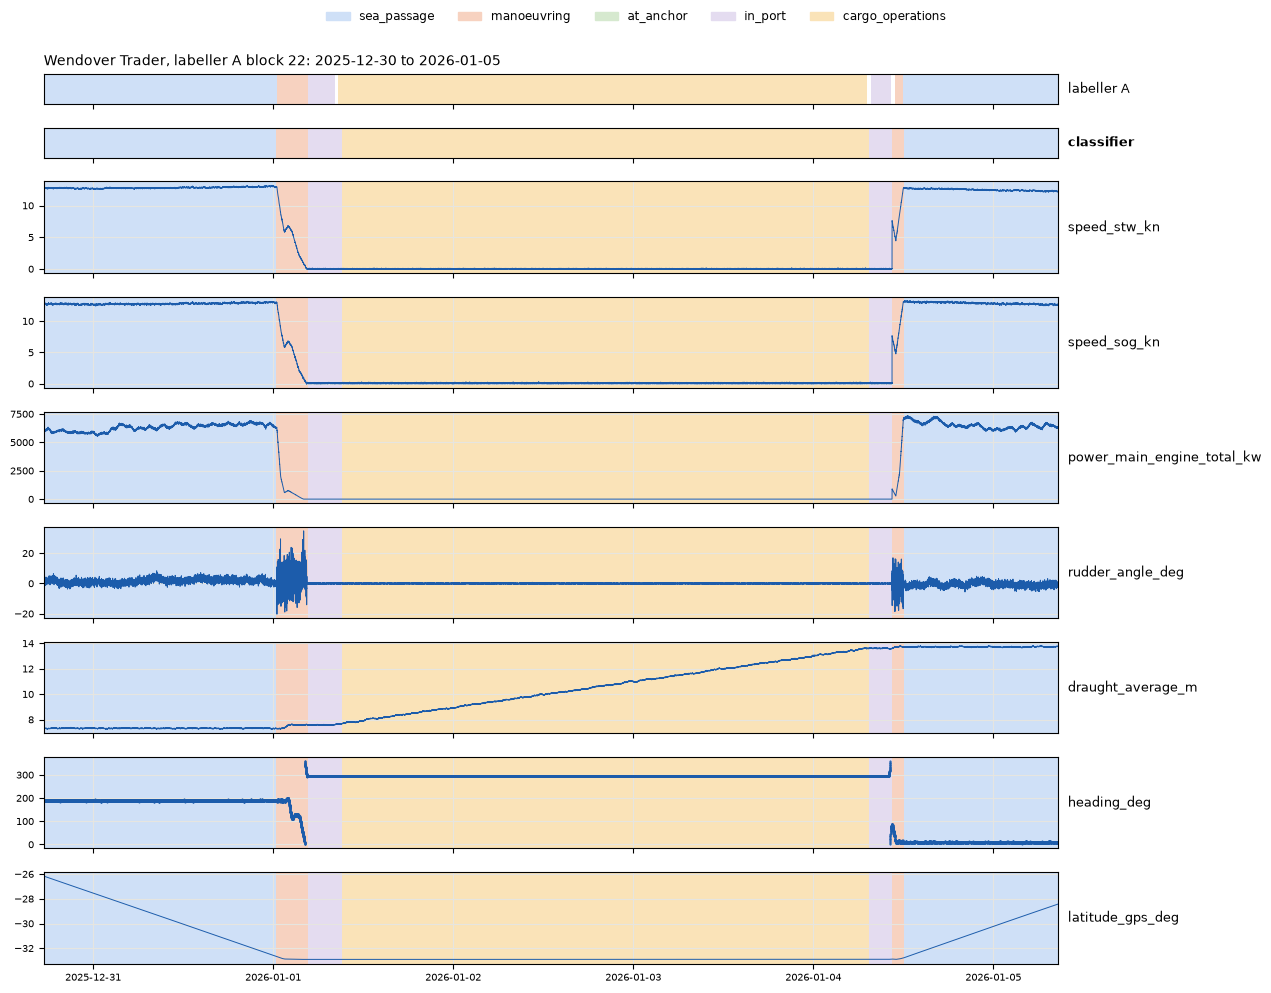

In [19]:
WHO = "A"     # whose blocks: "A" or "B"
PICK = 22      # block index, as in A_blocks / B_blocks


def label_blocks(who):
    """Blocks as in shot.ipynb: per vessel, stretches less than 6 h apart form one block."""
    raw_labels = pd.read_csv(ROOT / "labels.csv", parse_dates=["start", "end"])
    w = (raw_labels[raw_labels["labelled_by"] == f"labeller {who}"]
         .sort_values(["vessel", "start"]).reset_index(drop=True))
    w["gap_h"] = (w["start"] - w.groupby("vessel")["end"].shift()).dt.total_seconds() / 3600
    w["block"] = ((w["gap_h"] > 6) | w["gap_h"].isna()).cumsum()
    out = w.groupby("block").agg(vessel=("vessel", "first"), start=("start", "min"), end=("end", "max"),
                                 modes=("mode", "nunique"), n=("mode", "size"))
    out["trained_on_h"] = [                       # anything above 0 is not an honest test
        ((train["vessel"] == slug(r.vessel)) & (train["timestamp"] >= r.start)
         & (train["timestamp"] < r.end)).sum() / 60
        for r in out.itertuples()]
    return w, out


A_stretches, A_blocks = label_blocks("A")
B_stretches, B_blocks = label_blocks("B")
stretches, table = (A_stretches, A_blocks) if WHO == "A" else (B_stretches, B_blocks)
display(table.round({"trained_on_h": 1}))

pick = table.loc[PICK]
v, start, end = slug(pick.vessel), pick.start, pick.end
print(f"labeller {WHO}, block {PICK}: {pick.vessel}, {start} to {end}")
if pick.trained_on_h > 0:
    print(f"WARNING: the model trained on {pick.trained_on_h:.0f} h of this block, "
          "so a good score here means little.")

pred, raw = predict_minutes(v, start, end)
pred_blocks = to_blocks(pred)
mine = stretches[stretches["block"] == PICK][["start", "end", "mode"]]

print(f"\nlabeller {WHO} says:")
display(mine.assign(duration=mine["end"] - mine["start"]).reset_index(drop=True))
print("classifier says:")
display(pred_blocks.round({"confidence": 2}))

# minute by minute, only where labeller WHO labelled
truth = label_at(pred.index, mine, "mode")
final = label_at(pred.index, pred_blocks, "mode")
ok = pd.notna(truth)
y = pd.Series(truth[ok], name=f"labeller {WHO}")
p = pd.Series(final[ok], name="classifier")
present = [m for m in MODES if m in set(y) | set(p)]
print(f"{np.mean(y.to_numpy() == p.to_numpy()):.1%} of {ok.sum() / 60:.1f} labelled hours agree")
display(pd.DataFrame({
    f"hours_{WHO}": [np.sum(y == m) / 60 for m in present],
    "hours_classifier": [np.sum(p == m) / 60 for m in present],
    "f1": f1_score(y, p, labels=present, average=None, zero_division=0),
}, index=present).round(2))
display(pd.crosstab(y, p))

lab_v = lab[(lab["vessel"] == v) & (lab["start"] < end) & (lab["end"] > start)]
plot_range(raw, pred_blocks, lab_v, start, end,
           f"{pick.vessel}, labeller {WHO} block {PICK}: {start:%Y-%m-%d} to {end:%Y-%m-%d}")